# 实验课 06：把学到的选位规则放回真实推理

前两课训练时，各索引器看到的 Q/K/V 都由完整模型预先算好。现在把已训练参数放回真实 Qwen：**本层少读得到不同的输出，后层便可能收到不同的输入；后层索引器必须在这份实际输入上继续工作。** 本课检查这个变化，不再更新任何参数。

这一步称 **G3c：训练后索引器接入与状态对照**，使用 4 份已经分析过的旧开发资料。A 每层完整读取；D-one 只让第 14 层使用训练后索引器；D0 让全部层用初始索引参数；D 让全部层用训练后参数。

少读时都保留开头 4 个和最近 64 个位置，再按请求第一步长度的 1/8 固定额外名额。索引从主 RoPE 前 Q/K 投影到 32 维，索引空间不额外旋转；这就是配置里的“索引位置设置 P0，r=32”。每条路径用自己算出的缓存独立推进。默认只读保存记录，不运行模型。

In [1]:
from pathlib import Path
import sys, json, ast
from IPython.display import display, Markdown, Code
ROOT=Path.cwd()
if not (ROOT/'scripts/g3c_report.py').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
import g3c_report as report
e=report.read_evidence();s=report.summarize(e)
print('run:',s['run_id'],'计算源码:',s['source_commit'])
print('范围:',s['scope'])
import sys
sys.path.insert(0, str(ROOT / "scripts"))
from teaching_display import details, show_figure


run: g3c-20261018T153929Z 计算源码: 514c8138d41c4001633e15f5ef4ab4250d44a4b0
范围: 4 old development docs, identical controlled token inputs; NOT free-generation accuracy


## 1. 怎样只比较读取造成的状态变化，而不混入不同的生成文字？

**问题。** 若 A 和 D 自由生成了不同 token，下一步 Q/K 的差别既可能来自少读，也可能来自输入文字已不同。怎样暂时分开这两件事？

**做法。** 各方法从同一份资料重新完整 Prefill，分别保存主 K/V。之后输入相同的问题，再输入 A 预先产生的同一串 16 个 token；即使遇 EOS 仍输入满 16 步。这叫本课的**控制序列**。它来自 A 当时的预测，不是标准答案。

例如某一步共同输入 token x：A 用自己的缓存算出词表分数，D 用自己的缓存算出另一份分数；即使两者最高分 token 不同，下一步仍给两者输入预存序列中的同一个 token y。我们只固定送进模型的 token，不固定本层 Q/K、注意力输出或新写入的 K/V。这样比较内部状态时，输入文字的分叉不会混进来；代价是这段过程不再是 D 自己的自由回答，所以不能评分。

控制序列之前先输入问句的 26 个 token 和模板尾部的 9 个 token；首个答案预测处是这 35 个后缀 token 的最后一个，即模板末尾的两个换行。

记录中的 **q/k** 取自每层 `q_norm/k_norm` 的输出，位于 RoPE 和转置之前。它们只属于本步新输入的一个位置，不是整张历史缓存。形状中的前两个 1 分别表示一份输入、一个新位置：Q 为 `[1,1,16,128]`，有 16 个查询头；K 为 `[1,1,8,128]`，有 8 个 K/V 头。比较时，Q 展平成 2,048 维，K 展平成 1,024 维。

**attention_output** 是 16 个查询头的读出拼接结果：每头 128 维，合计 `16×128=2048`，形状为 `[1,1,2048]`。代码在 `o_proj` 之前捕获它；之后原来的 `o_proj` 将 2,048 维映射回模型的 1,024 维隐藏表示。

因此本课的读出相对 L2 比较的是**同一位置、整个注意力层的 2,048 维向量**；第四、五课则先按每个 KV 组的 256 维向量算误差，再平均。两者的向量范围及平均顺序不同，不能把这两个数直接当成同一种误差比较。

资料仍是 **T1：按编号返回一个四位值**，如 `G3a-T1-2K-48` 表示旧单层阶段的第 48 份约 2K 资料。输出 `controlled_not_quality` 标记这条延续输入不能当作独立回答。

**得到什么。** 四份资料都形成了按同一输入位置对齐的状态记录，可以逐层比较 A、D-one、D0、D 的向量。比如资料 48 的控制串包含 `6692`、EOS 和后续文本，因为它被固定输入满 16 步；不能把这串文字当作 D 自己答出的答案。


In [2]:
d=e['docs'][0];sequence=next(x for x in e['sequences'] if x['doc_id']==d['doc_id'])
print('资料：',d['doc_id'],'；资料前缀',d['prefix_token_count'],'token')
print(d['question'])
print('目标记录：',d['target_ids'][0],'→',d['targets'][0])
print('共同输入的 16 个控制 token 解码为：',repr(sequence['continuation_text']))
print('序列包含 EOS 后的内容，因为这里输入满 16 步做状态对齐；它不是一条自由回答。')
with details('展开问题与模板 token ID、原序列标签及主体检查'):
    print('问题/模板后缀：',d['suffix_ids'])
    print('原记录标签：',sequence['role'])
    print('主体参数相同：',e['manifest']['body_hash_before']==e['manifest']['body_hash_after'])

资料： G3a-T1-2K-48 ；资料前缀 2005 token
问题：编号 5270 对应的数值是多少？只输出该编号对应的四位数值，不要输出编号。
目标记录： 5270 → 6692
共同输入的 16 个控制 token 解码为： '6692<|im_end|>\n<|endoftext|>Human: 问题：编号 52'
序列包含 EOS 后的内容，因为这里输入满 16 步做状态对齐；它不是一条自由回答。


## 2. 参数固定，还必须保证缓存属于这份参数

**问题。** 历史索引键 z 是用 Wk 算出来的；若加载另一套参数，却继续读旧 z，所得分数就不是那套参数应有的分数。

**做法与结论。** 加载时核对各层参数的文件指纹、形状和数值，创建索引缓存时绑定参数身份，继续写入前检查仍是同一套参数；不一致就拒绝使用。因此本轮 D0、D 分别用自己的固定参数和索引表推进，主 K/V 为 bf16、索引为 fp32。

<details>
<summary>展开参数身份保护</summary>

z=Wk·k_pre；更换 Wk 后沿用旧 z，会把新查询投影与旧键投影混用。本项目 `FrozenBank` 保存各层固定索引参数，加载时核对文件指纹与形状，创建缓存时绑定参数身份，写入前检查身份仍一致。

本轮主 K/V 为 bf16，索引 z 和投影为 fp32。

</details>


In [3]:
source=e['files'][f"source/{s['source_commit']}/src/attention_lab/trained.py"].decode()
node=next(x for x in ast.parse(source).body if getattr(x,'name',None)=='FrozenBank')
display(Code(ast.get_source_segment(source,node),language='python'))

class FrozenBank:
    def __init__(self, indexes, *, identity):
        self.indexes = list(indexes)
        self.identity = identity
        self._objects = tuple(id(x) for x in self.indexes)

    def guard(self, state):
        if tuple(id(x) for x in state.indexers) != self._objects:
            raise RuntimeError("state index bank changed")
        for index in self.indexes:
            index.verify()
            if index.wk.device != state.cache.device:
                raise RuntimeError("index/cache devices differ")
        cache = state.cache
        if not cache.has_index or cache.index_dtype != torch.float32:
            raise RuntimeError("bank requires a float32 index cache")
        if cache.valid_length and getattr(cache,"index_identity",None) != self.identity:
            raise RuntimeError("prefix index cache belongs to different parameter identity")
        cache.index_identity = self.identity

## 3. 让 D 读齐所有位置，能否回到 A 的结果？

**问题。** 全选时没有遗漏位置，若 D 仍与 A 不同，差异就不能归因于“少读了历史”。

**做法。** 分别让只改第 14 层的 D-one、改全部层的 D 获得全部候选名额，仍实际执行取 K/V 和主注意力。逐步比较 35 个问题/模板 token 加 16 个控制 token 的词表分数。初次发现差异后，只把同一个入选集合改为按原位置升序读取，再做相同比较。

**结果与结论。** 排序后两种全选路径的 51 步词表分数均与 A 逐位一致。该输入下的接入检查通过，说明实现中的位置排列也会影响有限精度结果；这没有增加名额，也不是训练收益，更不证明真正少读时仍会相同。

<details>
<summary>展开失败定位、修复与全选判据</summary>

先把候选名额给足，使 D-one/D 读取全部合法位置，仍走实际 gather 和主注意力。这是本课的**全选检查**。

初次检查失败时，筛选结果按分数排列，A 按原位置排列；记录里的首次差异出现在第 14 层读出。随后唯一的读取修复是将已选集合按原位置升序送入主注意力，未增加位置、改变名额或放宽容差。修后单层/全层全选的 51 个输入步均与 A logits 逐位一致；51 步包括问题/模板后缀和 16 个控制 token。

这证明该固定输入下的全选对应关系；不把排序修复算成训练收益。表中 `max_abs_logits/max_relative_logits/argmax_agreement` 对应绝对分数差、相对分数差和最高分 token 一致率。

</details>


In [4]:
lines=['| 全选检查 | 输入步数 | 词表分数最大差 | 相对差 | argmax 一致率 |','|---|---:|---:|---:|---:|']
for row in s['full_selection']:
    lines.append(f"| {row['method']} | {row['steps']} | {row['max_abs_logits']:.6f} | {row['max_relative_logits']:.6f} | {row['argmax_agreement']:.1%} |")
display(Markdown('\n'.join(lines)))
with details('展开首次失败记录与原有容差'):
    print(s['failed_runs']);print(e['manifest']['full_selection_tolerance'])

| 全选检查 | 输入步数 | 词表分数最大差 | 相对差 | argmax 一致率 |
|---|---:|---:|---:|---:|
| D-one | 51 | 0.000000 | 0.000000 | 100.0% |
| D | 51 | 0.000000 | 0.000000 | 100.0% |

## 4. 少读在哪一层改变了读出，又在哪一层改变了查询？

**问题。** 第五课的索引器是在完整路径的 Q/K 上学的。放回模型后，它们从什么时候开始面对已经改变的输入？

**做法。** 固定同一输入 token，分别捕获各方法每层读取前的 Q/K 和读取后的注意力向量，与 A 的同层同位置比较。下图取问题及聊天模板后缀的最后一个 token，即首个答案预测处，汇总四份资料。

**结果。** D-one 的第 1—14 层 Q 差异为零，第 14 层注意力读出已有差异，第 15 层起 Q 也不同。全层 D 更早：第 1 层读出就改变，第 2 层 Q 已不同。

每种向量先对同一步 A 算相对 L2，再平均 4 份资料。表还列出两个对齐位置：**first_answer_prediction** 是问题及聊天模板后缀的最后一个 token 后，**last_controlled_step** 是第 16 个控制 token 后。

<!-- lesson06-mechanism-svg: source reports/figures/06_readout_then_next_layer.svg -->
<figure id="readout-then-next-layer" style="width:50%;max-width:50%;min-width:0;margin:24px auto;">
  <div role="region" aria-label="图 6-1。本层读出先改变，下一层的 Q 才开始不同" tabindex="0" style="width:100%;max-width:100%;box-sizing:border-box;border:1px solid #dce3ec;border-radius:12px;background:#fff;">
    <img alt="图 6-1。两种方法处理相同输入token，各自维护缓存。保存的首个答案预测位置上，前13层完整计算使第14层输入与Q相同。第14层A读取全部K/V，D-one读取入选K/V，其注意力读出已有差异。经过输出投影、残差、MLP后，第15层输入与Q出现差异。新读出不会倒流修改已计算的本层K/V。此图描述保存记录的层间顺序，不定位具体错误或信息中转位置。" width="1440" height="1110" src="" style="display:block;width:100%;max-width:100%;min-width:0;height:auto;" />
  </div>
  <figcaption style="margin-top:10px;color:#475569;font-size:0.95em;line-height:1.6;text-align:center;"><strong>图 6-1。</strong>纵向箭头是计算顺序，横线比较两条路径同一步的向量。图中“已不同”对应现存记录，不指定信息传播经过了哪个历史位置。 <a href="../reports/figures/06_readout_then_next_layer.svg">打开 SVG 原图</a>。</figcaption>
</figure>
<!-- /lesson06-mechanism-svg -->

**结论。** 少读后的向量继续经过输出投影、残差和 MLP，成为下一层输入；后层索引器实际收到的特征因此不再完全是训练时的完整路径特征。本层读出不会倒流改写已经生成的本层 K/V。这些记录定位了层间差异从哪里开始，尚未定位具体错题的信息传播路径。


| 对齐位置 | 方法 | 第14层Q差异 | 第28层Q差异 | 第28层读出差异 | logits差异 | argmax相同 |
|---|---|---:|---:|---:|---:|---:|
| 首个答案预测 | D0 | 0.1686 | 0.2232 | 0.5875 | 0.4804 | 1/4 |
| 首个答案预测 | D-one | 0.0000 | 0.0141 | 0.0321 | 0.0344 | 4/4 |
| 首个答案预测 | D | 0.0651 | 0.0519 | 0.1548 | 0.1071 | 4/4 |
| 第16个控制输入后 | D0 | 0.3329 | 0.1076 | 0.3563 | 0.2632 | 3/4 |
| 第16个控制输入后 | D-one | 0.0000 | 0.0085 | 0.0244 | 0.0154 | 4/4 |
| 第16个控制输入后 | D | 0.1728 | 0.0431 | 0.1518 | 0.1070 | 4/4 |


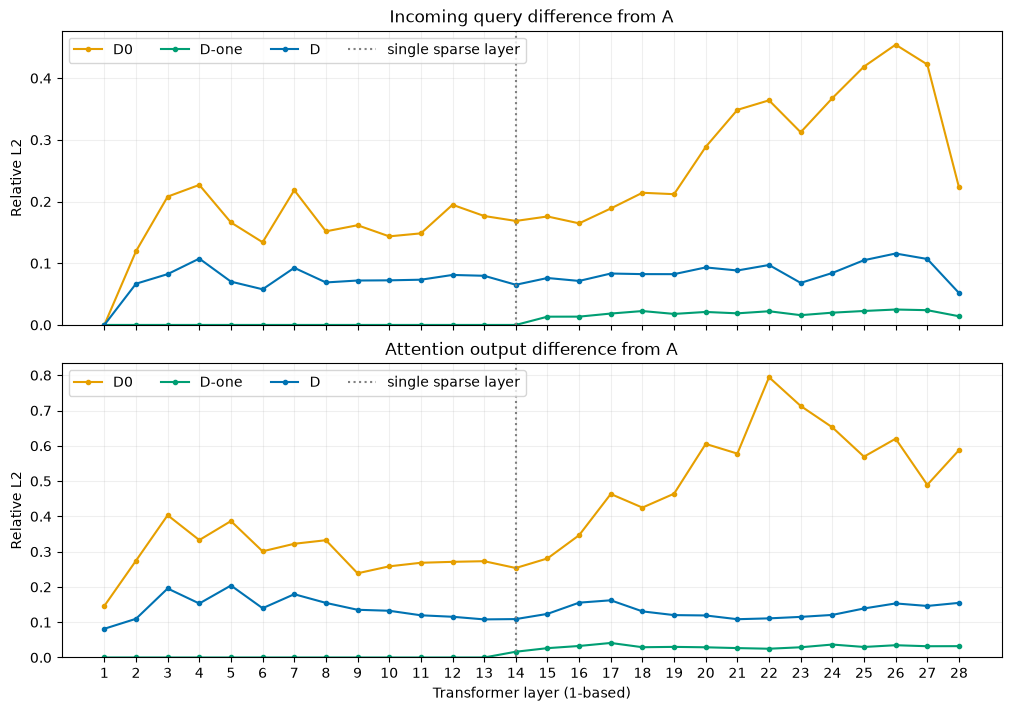

In [5]:
display(Markdown(report.table(s)))
import matplotlib.pyplot as plt
fig=report.plot(s)
show_figure(fig, "6-2", "首个答案预测处的逐层 Q 与注意力读出差异")


## 5. 训练后的参数在真实状态上，是否仍比 D0 更接近 A？

**问题与做法。** 前层输出已经改变，后层还用自己的状态计算时，训练收益是否仍能体现在最终词表分数？在首个答案预测处和第 16 个控制输入后，分别计算 D0、D、D-one 相对 A 的词表向量差，再对四份资料平均。

**结果。** 首个答案预测处，最终词表分数相对 A 的平均 L2 差异为 D0 0.4804、D 0.1071、D-one 0.0344；控制序列末步分别约 0.2632、0.1070、0.0154。

**结论。** 训练后的参数在这两个对齐点仍比 D0 更接近 A，改善没有在进入真实状态后完全消失。但这里只用了 4 份旧开发资料，不能推成所有层、所有步骤或新任务都更好。

D 在首个预测处与 A 的 argmax 都相同，也只是 4 份资料这一位置的一致率；后续输入被固定，尚未检验各方法自由生成分叉后的答案。第七课 **G4-lite** 用预先固定的 32 份新 T1 比较各方法自由回答，保留 A 错误及 D 改善/退化的题，不据结果再调参。

<details>
<summary>后续方法与预算标签</summary>

这里 B/C 指近期窗口/均匀随机；旧 G3a 账指第四课单层训练，共享预算累计第五至七课实际运行。

</details>

In [6]:
print('共享设备秒数:',s['budget']['used_seconds'],'/',s['budget']['limit_seconds'])
print('报告重建: python scripts/g3c_report.py')
print('本课图已从记录绘制；整页和窄屏验收状态见PROJECT_STATUS。')

共享设备秒数: 3586.606224249932 / 14400
报告重建: python scripts/g3c_report.py
本课图已从记录绘制；整页和窄屏验收状态见PROJECT_STATUS。
